In [97]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [98]:
# 1. Generate dataset (binary classification, 2 features)
X, y = make_classification(
    n_samples=1000, 
    n_features=2, 
    n_redundant=0, 
    n_informative=2, 
    n_clusters_per_class=1, 
    random_state=42
)

print(X.shape)
print(y.shape)

(1000, 2)
(1000,)


In [99]:
X[:5]

array([[ 0.60103418,  1.5353525 ],
       [ 0.75594526, -1.1723519 ],
       [ 1.35447877, -0.94852841],
       [ 3.1030897 ,  0.23348484],
       [ 0.75317779,  0.78751427]])

In [100]:
y[:5]

array([1, 0, 0, 0, 1])

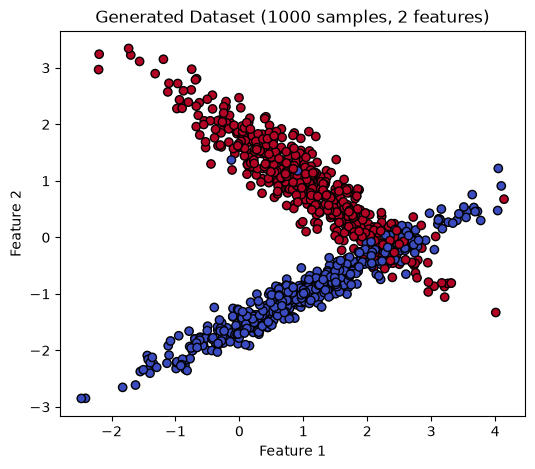

In [101]:
# 2. Plot dataset
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
plt.title("Generated Dataset (1000 samples, 2 features)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [120]:
# 3. Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# 4. Train SVM
svm_model = SVC(kernel='rbf') ## you can use linear, rbf and poly kernels
svm_model.fit(X_train, y_train)

rf_clf = RandomForestClassifier(n_estimators=50, random_state=42)
rf_clf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [121]:
# 5. Predictions
y_pred = svm_model.predict(X_test)
y_pred_rf = rf_clf.predict(X_test)

# 6. Evaluation metrics SVM
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Evaluation metrics RF
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("📊 Model Evaluation Metrics of SVM:")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")


print("📊 Model Evaluation Metrics of Random Forest:")
print(f"Accuracy:  {acc_rf:.4f}")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall:    {rec_rf:.4f}")
print(f"F1 Score:  {f1_rf:.4f}")


📊 Model Evaluation Metrics of SVM:
Accuracy:  0.9350
Precision: 1.0000
Recall:    0.8713
F1 Score:  0.9312
📊 Model Evaluation Metrics of Random Forest:
Accuracy:  0.9450
Precision: 0.9592
Recall:    0.9307
F1 Score:  0.9447


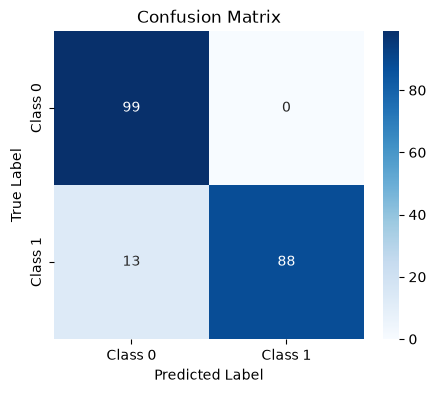

In [122]:
# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.title("Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

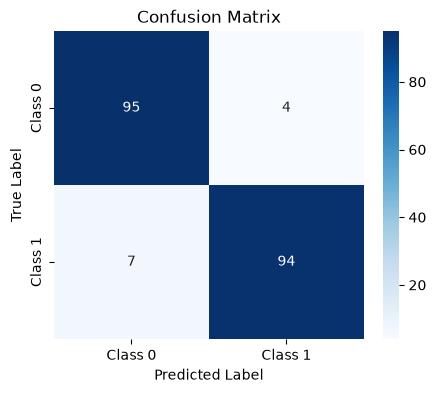

In [123]:
# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.title("Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

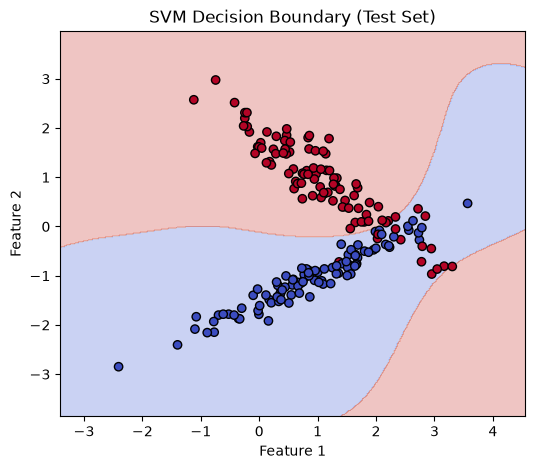

In [124]:
# 8. Plot decision boundaries
def plot_decision_boundary(model, X, y, title="Decision Boundary"):
    h = 0.02  # step size
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

plot_decision_boundary(svm_model, X_test, y_test, "SVM Decision Boundary (Test Set)")


## **SVM From Scratch**

In [125]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Generate dataset
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=42
)
print(X.shape)
print(y.shape)

(1000, 2)
(1000,)


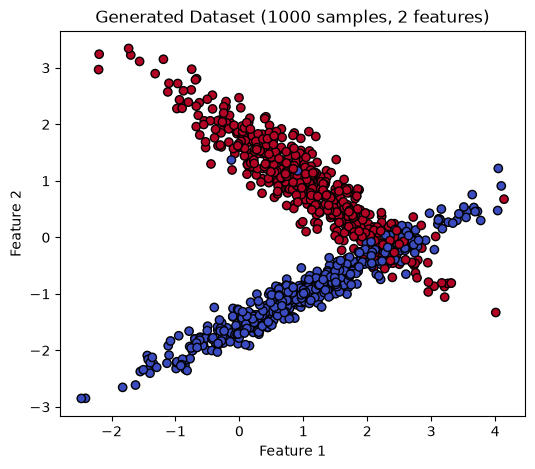

In [126]:
# 2. Plot dataset
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
plt.title("Generated Dataset (1000 samples, 2 features)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [127]:
y[:10]

array([1, 0, 0, 0, 1, 1, 0, 1, 1, 1])

In [128]:
# Convert labels from {0,1} to {-1,+1} (required for SVM hinge loss)
y = np.where(y == 0, -1, 1)

# 2. Train-test split
split_ratio = 0.8
n_train = int(split_ratio * len(X))
X_train, X_test = X[:n_train], X[n_train:]
y_train, y_test = y[:n_train], y[n_train:]

print(y[:10])
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

[ 1 -1 -1 -1  1  1 -1  1  1  1]
(800, 2)
(800,)
(200, 2)
(200,)


In [132]:
import numpy as np

w = np.zeros(X_train.shape[1])   # weights
# w = np.random.randn(X_train.shape[1]) * 0.01  # initialize weights with random values
b = 0.0                          # bias
lr = 0.001                       # learning rate
epochs = 2000                    # iterations
C = 5                          # regularization strength

## Training loop (SGD on hinge loss)
M = len(X_train)
for epoch in range(epochs):
    for i in np.random.permutation(M):
        margin = y_train[i] * (X_train[i] @ w + b)
        if margin >= 1:
            # Hinge loss inactive → only regularizer contributes
            dw = w / M              # gradient of (1/2)*||w||^2
            db = 0.0
        else:
            # Hinge loss active → regularizer + penalty term
            dw = w / M - C * y_train[i] * X_train[i]
            db = -C * y_train[i]
        w -= lr * dw
        b -= lr * db


In [131]:
np.random.permutation(M)

array([ 31, 513, 129, 685,  26, 334,  73, 714, 701, 350, 654, 611,  51,
       694, 578, 740, 368,  60, 288, 772, 152, 130, 553, 255,  21, 461,
        45,  47, 120, 323, 406, 167, 491,  19, 417, 235,  79, 692, 541,
       749,  27, 656, 731, 105,  41, 519, 579, 353, 375, 366, 400,  72,
       439, 374, 667, 194, 360, 748, 385, 688, 248, 757, 621, 570, 403,
       708, 372, 349, 533, 484, 508, 717, 363,  40, 733, 266, 155, 387,
       117, 331, 762, 576, 632, 470, 475, 485, 423,  11, 623, 433, 645,
       283, 741, 162, 240, 230, 529, 486, 534, 539, 294, 177, 499, 418,
       143, 536, 658, 764, 265, 504, 348, 408, 535, 712, 207, 317, 790,
       361,  12, 424,  92, 267, 215, 588, 136, 287, 337, 690, 428, 548,
       609,  62, 551, 734, 426, 201, 648, 411, 221, 784, 725,  67,  54,
       791,  88, 538, 630, 695, 127, 601, 558, 618,  68, 381, 455, 238,
       641, 793, 603, 469, 781, 699, 178, 735, 560, 693,  90, 544, 683,
       330, 310, 510, 732, 767, 583, 780, 380, 467, 198,  16, 62

In [133]:
# 5. Predictions
y_pred = np.sign(np.dot(X_test, w) + b)

# Convert back {-1,+1} → {0,1} for metrics
y_test_metrics = np.where(y_test == -1, 0, 1)
y_pred_metrics = np.where(y_pred == -1, 0, 1)

# 6. Evaluation
acc = accuracy_score(y_test_metrics, y_pred_metrics)
prec = precision_score(y_test_metrics, y_pred_metrics)
rec = recall_score(y_test_metrics, y_pred_metrics)
f1 = f1_score(y_test_metrics, y_pred_metrics)

print("📊 Model Evaluation (Scratch SVM)")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")


📊 Model Evaluation (Scratch SVM)
Accuracy:  0.9400
Precision: 0.9775
Recall:    0.8969
F1 Score:  0.9355


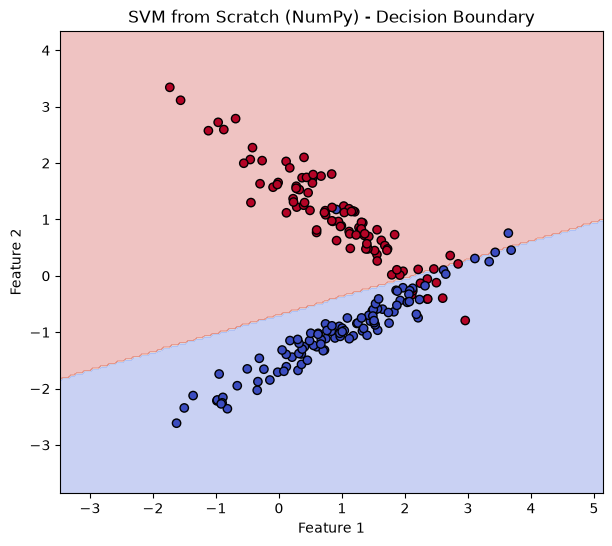

In [134]:
# 7. Plot decision boundary
x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

Z = np.sign(np.dot(np.c_[xx.ravel(), yy.ravel()], w) + b)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(7,6))
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.3)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.coolwarm, edgecolors="k")
plt.title("SVM from Scratch (NumPy) - Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

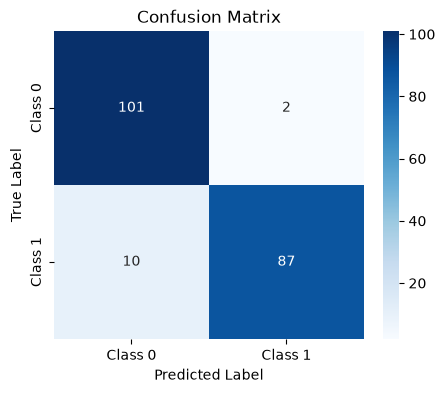

In [135]:
# 7. Confusion Matrix
cm = confusion_matrix(y_test_metrics, y_pred_metrics)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.title("Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()